<a href="https://colab.research.google.com/github/Diego230703/S8-Student-Version-Project-NovaRetail/blob/main/S8_Student_Version_Project_NovaRetail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto 7 - Explorando factores de comportamiento en NovaRetail+


NovaRetail+ es una plataforma de comercio electrónico en Latinoamérica con millones de usuarios.

Para el cierre de 2024, el equipo de **Crecimiento y retención** tiene como objetivo responder:

**¿Qué factores del comportamiento del cliente están más fuertemente asociados con el ingreso anual generado?**

> Este proyecto es un análisis **correlacional** (exploratorio).  
> **Correlación ≠ causalidad.**

## Sección 1 - Cargar y explorar el dataset

En esta sección validamos:
- que el dataset cargue correctamente
- tipos de datos
- valores faltantes / rangos generales

Antes de correlacionar, primero entendemos el “terreno”.

In [ ]:
# Importar librerías
from scipy.stats import pointbiserialr
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Cargar Dataset

In [ ]:
# Cargar el dataset y explorar datos
df = pd.read_csv('/datasets/novaretail_comportamiento_clientes_2024.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  float64
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(5), int64(4), object(3)
memory usage: 1.4+ MB


#### Descripción del conjunto de datos

El dataset contiene las siguientes columnas:

- `id_cliente` — Identificador único del cliente.
- `edad` — Edad del cliente.
- `nivel_ingreso` — Ingreso anual estimado del cliente.
- `visitas_mes` — Número de visitas a la aplicación o sitio web durante el mes.
- `compras_mes` — Número de compras realizadas en el mes.
- `gasto_publicidad_dirigida` — Gasto en anuncios asignado al usuario.
- `satisfaccion` — Calificación de satisfacción del cliente en una escala del 1 al 5.
- `miembro_premium` — Indica si el cliente tiene suscripción premium (1) o no (0).
- `abandono` — Indica si el cliente abandonó la plataforma (1) o no (0).
- `tipo_dispositivo` — Tipo de dispositivo utilizado por el cliente (móvil, escritorio o tablet).
- `region` — Región geográfica del cliente (norte, sur, oeste o este).
- `ingreso_anual` — Ingreso anual generado por el cliente para la empresa.

La métrica principal de análisis es `ingreso_anual`, utilizada para evaluar el impacto económico de los clientes.


In [ ]:
# mostrar las primeras 5 filas
df.head(5)

,id_cliente,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,miembro_premium,abandono,tipo_dispositivo,region,ingreso_anual
0,CL-100000,44.0,28565.77,9,1,31.36,3.9,0,0,móvil,norte,23.22
1,CL-100001,36.0,29673.44,11,3,24.66,3.7,0,0,tablet,sur,93.47
2,CL-100002,46.0,30642.95,9,0,0.00,2.9,0,0,móvil,este,0.00
3,CL-100003,56.0,39468.61,8,0,6.81,3.1,0,0,móvil,este,0.00
4,CL-100004,35.0,22527.83,9,2,26.49,2.3,0,0,móvil,sur,33.76


## Sección 2 - Preparar datos y documentar supuestos

### Exploración y Limpieza

💡
Después de analizar la información anterior, completa la siguiente sección.  
- Si aplica, señala la o las columnas que requieren algun cambio

Recuerda eliminar este bloque de texto antes de subir el proyecto a tu portafolio.


#### Exploración inicial de los datos
El conjunto de datos contiene **15,000 registros** y **12 columnas**, sin valores nulos.

**Variables numéricas**  
Se identifican las siguientes columnas numéricas:
- `edad`
- `nivel_ingreso`
- `visitas_mes`
- `compras_mes`
- `gasto_publicidad_dirigida`
- `satisfaccion`
- `ingreso_anual`

La mayoría de estas variables presentan tipos de datos adecuados.  
La columna `edad` aparece como decimal, cuando se esperaría que sea un número entero.


**Variables binarias**  
Las siguientes columnas representan variables binarias:
- `miembro_premium`
- `abandono`

Ambas están codificadas como 0 y 1, **no requieren transformación adicional**.

**Variables categóricas**  
Se identifican las siguientes columnas categóricas:
- `id_cliente`
- `tipo_dispositivo`
- `region`

Estas variables están correctamente definidas y no requieren transformación adicional.

In [ ]:
# Corregir el tipo de dato
df['edad'] = df['edad'].astype(int)

In [ ]:
# verificar cambios
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_cliente                 15000 non-null  object 
 1   edad                       15000 non-null  int64  
 2   nivel_ingreso              15000 non-null  float64
 3   visitas_mes                15000 non-null  int64  
 4   compras_mes                15000 non-null  int64  
 5   gasto_publicidad_dirigida  15000 non-null  float64
 6   satisfaccion               15000 non-null  float64
 7   miembro_premium            15000 non-null  int64  
 8   abandono                   15000 non-null  int64  
 9   tipo_dispositivo           15000 non-null  object 
 10  region                     15000 non-null  object 
 11  ingreso_anual              15000 non-null  float64
dtypes: float64(4), int64(5), object(3)
memory usage: 1.4+ MB


#### Explorar variables numéricas

In [ ]:
# Estadísticas descriptivas de variables numéricas
columnas_numericas = ['edad', 'nivel_ingreso', 'visitas_mes', 'compras_mes', 'gasto_publicidad_dirigida',
                     'satisfaccion', 'ingreso_anual']

df[columnas_numericas].describe()

,edad,nivel_ingreso,visitas_mes,compras_mes,gasto_publicidad_dirigida,satisfaccion,ingreso_anual
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,38.262400,30019.704782,10.029000,1.206467,20.149301,3.603693,36.594180
std,11.492378,9833.166305,3.158189,1.105284,10.880724,0.685300,34.484888
min,18.000000,8000.000000,1.000000,0.000000,0.000000,1.000000,0.000000
25%,30.000000,23127.097500,8.000000,0.000000,12.310000,3.100000,0.000000
50%,38.000000,30023.745000,10.000000,1.000000,19.730000,3.600000,30.705000
75%,46.000000,36768.440000,12.000000,2.000000,27.292500,4.100000,58.220000
max,75.000000,74790.840000,25.000000,8.000000,75.510000,5.000000,244.690000


Diagnóstico inicial de variables numéricas

- `edad` — Los valores van de 18 a 75 años, un rango completamente realista para clientes adultos. La media (38.26) es casi idéntica a la mediana (38.0), lo que refleja una distribución simétrica y sin sesgos extremos hacia la mitad baja del rango. Por su parte, la desviación estándar (11.49) es moderada frente al rango total, indicando una dispersión razonable de las edades.
- `nivel_ingreso` — El rango va desde 8,000 USD hasta 74,790.84 USD, con una media (30,019.70 USD) y mediana (30,023.75 USD) prácticamente iguales. La desviación estándar (9,833.17 USD) es moderada respecto al rango total, mostrando que la mayoría de los clientes se concentran en un nivel de ingresos medio sin valores atípicos exagerados.
- `visitas_mes` — Los clientes visitan entre 1 y 25 veces al mes, con un promedio de 10.03 visitas que coincide con la mediana (10.0). Su desviación estándar es baja (3.16), lo que sugiere un comportamiento de navegación bastante estable y predecible entre la mayoría de los usuarios.
- `compras_mes` — El número de compras oscila entre 0 y 8 al mes, con una media de 1.21 y una mediana de 1.0 (además de que al menos el 25% de los clientes no realiza compras). La desviación estándar (1.11) es casi igual a la media, reflejando que la gran mayoría hace muy pocas compras al mes y solo un grupo reducido llega al máximo.
- `gasto_publicidad_dirigida` — Presenta un mínimo de 0.00 USD y un máximo de 75.51 USD, con una media (20.15 USD) muy cercana a la mediana (19.73 USD). La desviación estándar (10.88 USD) muestra una dispersión moderada, aunque el valor máximo está bastante alejado del 75% de los datos (27.29 USD), indicando algunos casos con inversión publicitaria más alta.
- `satisfaccion` — Se mueve en una escala lógica de 1.0 a 5.0 puntos, con una media (3.60) y mediana (3.60) idénticas ubicadas por encima del punto medio de la escala. Tiene una desviación estándar muy baja (0.69), lo que indica que las calificaciones son bastante consistentes y mayoritariamente positivas.
- `ingreso_anual` — Es la variable con mayor asimetría: va de 0.00 USD a 244.69 USD, pero al menos el 25% de los registros son cero (clientes sin compras) y la media (36.59 USD) es mayor que la mediana (30.71 USD). Su alta desviación estándar (34.48 USD), casi igual a la media, confirma una fuerte dispersión impulsada por un grupo pequeño de clientes que generan ingresos muy altos.

**Nota:** Las 7 columnas tienen exactamente 15,000 registros completos, por lo que no hay valores nulos en ninguna de ellas.

#### Explorar variables binarias

In [ ]:
# Verificar que cada columna tenga únicamente dos valores posibles
print(df['miembro_premium'].value_counts())
print(df['abandono'].value_counts())

0    12911
1     2089
Name: miembro_premium, dtype: int64
0    12739
1     2261
Name: abandono, dtype: int64


Diagnóstico inicial de variables binarias

- `miembro_premium` — Presenta un fuerte desbalance: el 86.1% de los clientes (12,911) no cuenta con suscripción (valor 0), mientras que solo el 13.9% (2,089) son miembros premium (valor 1), lo que indica que la gran mayoría utiliza la modalidad gratuita o estándar de la plataforma.
- `abandono` — También muestra una distribución desbalanceada: el 84.9% de los usuarios (12,739) permanece activo (valor 0) frente al 15.1% (2,261) que abandonó la plataforma (valor 1), lo cual representa una tasa de cancelación (churn) moderada que vale la pena analizar a fondo.

#### Explorar variables categóricas

In [ ]:
# Verificar el número de valores únicos por variable categórica
print(len(df['tipo_dispositivo'].unique()))
print(len(df['region'].unique()))

3
4


In [ ]:
# Explorar variables categóricas y cómo se distribuyen
print(df['tipo_dispositivo'].value_counts())
print(df['region'].value_counts())

móvil         9818
escritorio    3720
tablet        1462
Name: tipo_dispositivo, dtype: int64
norte    4395
oeste    3810
sur      3726
este     3069
Name: region, dtype: int64


Diagnóstico inicial de variables categóricas

- `tipo_dispositivo` — Cuenta con 3 categorías limpias (`móvil`, `escritorio` y `tablet`) y presenta un fuerte desbalance: el 65.5% de los usuarios (9,818) accede desde `móvil`, frente al 24.8% (3,720) en `escritorio` y apenas el 9.7% (1,462) en `tablet`. En términos de negocio, esto evidencia que la experiencia móvil es el canal principal de interacción y donde debe priorizarse la optimización de la plataforma.
- `region` — Se divide en 4 categorías (`norte`, `oeste`, `sur` y `este`) con una distribución bastante equilibrada entre ellas: `norte` lidera ligeramente con el 29.3% (4,395), seguida de `oeste` con 25.4% (3,810), `sur` con 24.8% (3,726) y `este` con 20.5% (3,069). Esto indica que la base de clientes está bien repartida geográficamente, sin una dependencia crítica de una sola zona.

### Supuestos

- El análisis se realiza utilizando **todo el conjunto de datos disponible**.
- Los datos no presentan errores y están correctamente tipificados.
- Se utilizan distintos coeficientes según el tipo de variable:
  - **Pearson** asume relaciones lineales entre variables numéricas.
  - **Spearman** evalúa relaciones monótonas y no requiere normalidad.
  - **Punto biserial** se usa para relaciones numérica–binaria.
  - **Cramér (V)** se usa para asociaciones entre variables categóricas.

**Supuesto central:**  
Este análisis identifica relaciones entre variables o segmentos, pero no prueba causalidad.

## Sección 3 - Visualización de relaciones

Observamos cómo se relacionan las variables numéricas.

### Heatmap

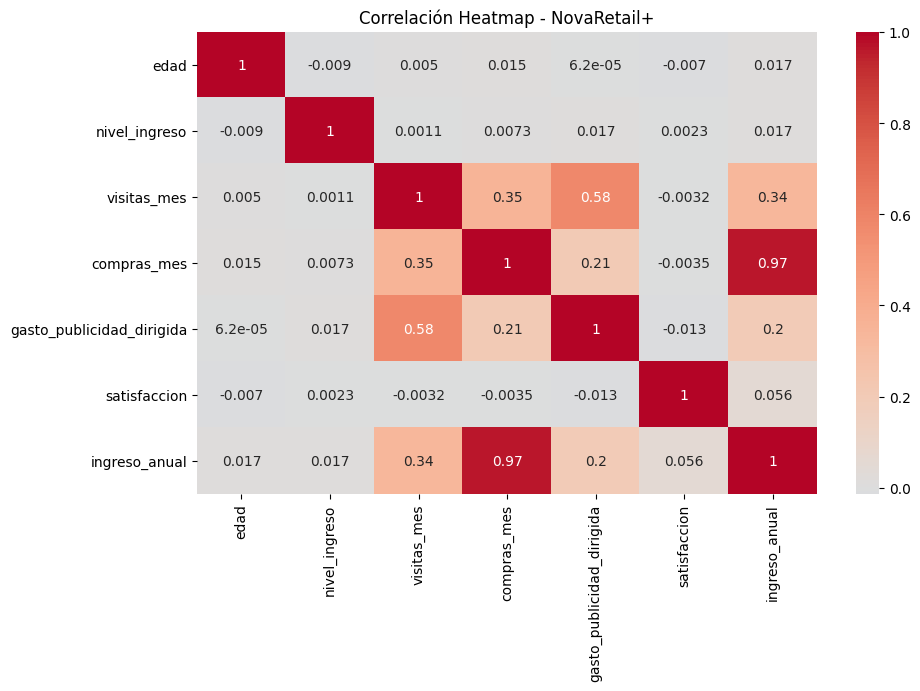

In [ ]:
# Visualizar la matriz de correlación para identificar relaciones
corr = df[columnas_numericas].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0)
plt.title("Correlación Heatmap - NovaRetail+")
plt.show()

Observaciones generales (Heatmap)
- Se observa una correlación positiva extremadamente fuerte entre `compras_mes` e `ingreso_anual` (0.97), lo que indica que ambas variables se mueven juntas de manera casi proporcional. También destaca una asociación positiva moderada entre `gasto_publicidad_dirigida` y `visitas_mes` (0.58), mostrando que los usuarios con mayor inversión publicitaria dirigida suelen registrar más visitas mensuales, así como una correlación positiva débil-moderada entre `visitas_mes` y `compras_mes` (0.35). Por otro lado, variables como `edad`, `nivel_ingreso` y `satisfaccion` presentan correlaciones prácticamente nulas (cercanas a 0) con el resto, lo que sugiere que no existe una relación lineal directa entre estos factores y la frecuencia de compra.

Observaciones respecto a `ingreso_anual`

- Presenta una asociación lineal muy estrecha con `compras_mes` (0.97), siendo la variable que mejor acompaña sus variaciones. Asimismo, muestra una correlación positiva moderada con `visitas_mes` (0.34) y débil con `gasto_publicidad_dirigida` (0.20), reflejando que un mayor nivel de interacción y alcance publicitario suele vincularse con mayores montos anuales. En contraste, su relación lineal con `edad` (0.017), `nivel_ingreso` (0.017) y `satisfaccion` (0.056) es prácticamente inexistente, por lo que estas características no muestran un patrón claro frente al gasto anual en la plataforma.

### Scatterplot general

**¿Por qué no se incluyo un Scatterplot general?**\
El heatmap ya da la magnitud y dirección de cada correlación de forma numérica y visual, por lo que un scatterplot general de todas las variables sería redundante en este caso. Además, con ~15000 filas sería visualmente denso y poco legible.

### Scatterplot para pares clave

<AxesSubplot:xlabel='compras_mes', ylabel='ingreso_anual'>

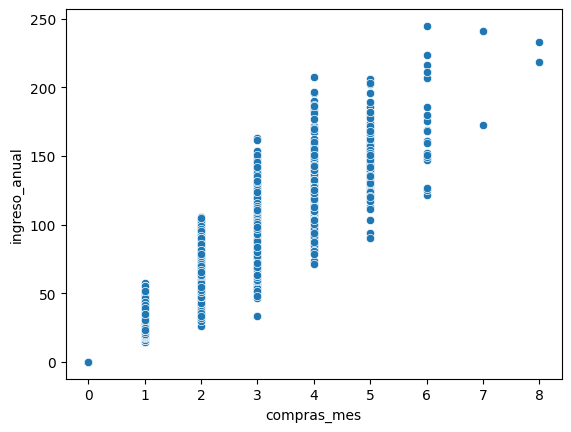

In [ ]:
# Visualizar pares de variables con relaciones moderadas o fuertes
sns.scatterplot(data=df,x='compras_mes', y='ingreso_anual')

<AxesSubplot:xlabel='visitas_mes', ylabel='gasto_publicidad_dirigida'>

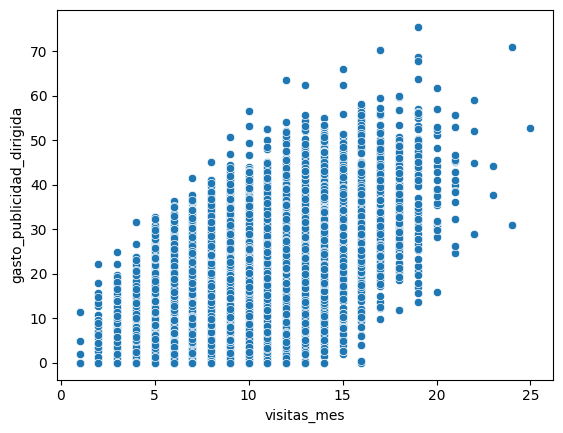

In [ ]:
sns.scatterplot(data=df,x='visitas_mes', y='gasto_publicidad_dirigida')

Observaciones iniciales (Scatterplot)

**compras_mes vs ingreso_anual**

- **Dirección:** Positiva; a medida que aumenta el número de compras mensuales, el ingreso anual crece de forma clara y ascendente.
- **Dispersión:** Baja; los puntos se agrupan de manera bastante compacta alrededor de una tendencia lineal ascendente (en franjas verticales debido a que `compras_mes` toma valores enteros), aunque la amplitud vertical crece ligeramente en los niveles más altos de compra.
- **Outliers:** No se observan valores atípicos aislados o fuera de la tendencia general; incluso los registros en el extremo superior derecho (7 y 8 compras al mes) siguen coherentemente la progresión lineal.
- **Colinealidad:** Muy alta (correlación de 0.97); ambas variables aportan información prácticamente redundante, por lo que en un modelo predictivo sería conveniente evaluar conservar solo una de ellas para evitar problemas de multicolinealidad.

**visitas_mes vs gasto_publicidad_dirigida**

- **Dirección:** Positiva; se aprecia una tendencia ascendente donde mayores niveles de visitas mensuales tienden a coincidir con un mayor gasto en publicidad dirigida.
- **Dispersión:** Media-alta; la nube de puntos es bastante ancha y presenta una forma de abanico (mayor variabilidad en el gasto publicitario a medida que aumentan las visitas), lo que concuerda con una correlación moderada (0.58).
- **Outliers:** No hay puntos extremos completamente desconectados del conjunto, aunque se observan algunos registros aislados en la parte superior (gastos cercanos a 70–75 USD) y en el extremo derecho (24–25 visitas) que sobresalen ligeramente de la densidad principal.
- **Colinealidad:** Baja a moderada (correlación de 0.58); aunque comparten cierta tendencia, no existe redundancia crítica y ambas variables aportan información complementaria al análisis.

## Sección 4 - Coeficientes de correlación y evidencia numérica

En esta sección, se reportan coeficientes que respaldan los patrones
observados visualmente, utilizando el método adecuado según el tipo
de variables.

### Pearson / Spearman

In [ ]:
# Calcular correlación entre variables relevantes
print(df[['compras_mes', 'ingreso_anual']].corr(method='pearson'))
print(df[['compras_mes', 'ingreso_anual']].corr(method='spearman'))

               compras_mes  ingreso_anual
compras_mes       1.000000       0.967149
ingreso_anual     0.967149       1.000000
               compras_mes  ingreso_anual
compras_mes       1.000000       0.967482
ingreso_anual     0.967482       1.000000


In [ ]:
# Calcular correlación entre variables relevantes
print(df[['visitas_mes', 'gasto_publicidad_dirigida']].corr(method='pearson'))
print(df[['visitas_mes', 'gasto_publicidad_dirigida']].corr(method='spearman'))

                           visitas_mes  gasto_publicidad_dirigida
visitas_mes                   1.000000                   0.578947
gasto_publicidad_dirigida     0.578947                   1.000000
                           visitas_mes  gasto_publicidad_dirigida
visitas_mes                   1.000000                   0.559267
gasto_publicidad_dirigida     0.559267                   1.000000


Observaciones de correlación

**compras_mes vs ingreso_anual**

- **Dirección y magnitud:** Correlación positiva muy fuerte, con valores prácticamente idénticos en Pearson (0.967) y Spearman (0.967). Esta coincidencia confirma que la relación entre ambas variables es estrictamente lineal y monótona, sin distorsiones por valores extremos.
- **Posible colinealidad:** Muy alta; al compartir casi toda su variabilidad, incluir ambas variables simultáneamente en un modelo predictivo generaría redundancia (multicolinealidad), por lo que se recomendaría seleccionar solo una.

**visitas_mes vs gasto_publicidad_dirigida**

- **Dirección y magnitud:** Correlación positiva moderada, con un coeficiente de Pearson de 0.579 y de Spearman de 0.559. La ligera diferencia entre ambos (siendo Pearson un poco mayor) sugiere que la relación no es perfectamente lineal y responde a la mayor dispersión en forma de abanico y a algunos registros altos observados previamente en el scatterplot.
- **Posible colinealidad:** Baja a moderada; no representa un problema de colinealidad crítica, por lo que ambas variables aportan información útil y diferenciada para el análisis.

### Punto-biserial

In [ ]:
# Calcular correlación entre variables relevantes
print(pointbiserialr( df['miembro_premium'], df['ingreso_anual']))
print(pointbiserialr( df['abandono'], df['ingreso_anual']))

SignificanceResult(statistic=0.0930994396198015, pvalue=3.0943076155242597e-30)
SignificanceResult(statistic=-0.002823934021617148, pvalue=0.7294691719078393)


Observaciones Punto-biserial

**miembro_premium vs ingreso_anual**

- **Dirección y magnitud:** Relación positiva muy baja (r = 0.093). El signo positivo indica que los clientes con suscripción premium (valor 1) tienden ligeramente a registrar un mayor ingreso anual que quienes no la tienen (valor 0), pero la magnitud es muy débil en comparación con variables como `compras_mes` (0.967).
- **Significancia:** El valor p (3.09e-30) es prácticamente cero (muy inferior a 0.05), lo que confirma que la diferencia es estadísticamente significativa gracias al gran tamaño de la muestra (15,000 registros), aunque su impacto práctico sea reducido.

**abandono vs ingreso_anual**

- **Dirección y magnitud:** Relación negativa prácticamente nula (r = -0.0028), muy cercana a cero, lo que indica que el ingreso anual no presenta una diferencia lineal observable entre los clientes que abandonan la plataforma y los que permanecen.
- **Significancia:** El valor p (0.729) es muy superior al umbral de 0.05, confirmando que esta mínima correlación no es estadísticamente significativa y puede deberse simplemente al azar.

### V de Cramér

In [ ]:
# Función para calcular V de Cramér
tabla = pd.crosstab(df['tipo_dispositivo'], df['region'])
chi2, p, dof, expected = chi2_contingency(tabla)
n = tabla.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(tabla.shape) -1)))

In [ ]:
# Aplicar V de Cramér en variables relevantes
print(cramers_v)

0.012378338407739397


Observaciones V de Cramér

* **tipo_dispositivo vs region** — Se obtuvo un coeficiente V de Cramér de 0.0124, un valor prácticamente igual a cero que indica ausencia de asociación entre ambas variables categóricas. En términos de negocio, esto significa que el tipo de dispositivo desde el cual acceden los clientes (móvil, escritorio o tablet) es independiente de la región geográfica en la que se encuentran, manteniendo proporciones de uso muy similares en todas las zonas.

## Sección 5 - Interpretación de resultados para el negocio
---

### 5.1 Hallazgo 1 — La frecuencia de compra mensual tiene una asociación directa y casi proporcional con el ingreso anual

**Evidencia visual:** El heatmap de correlación (Sección 3.1) muestra la relación más intensa de todo el conjunto de datos entre `compras_mes` e `ingreso_anual`, mientras que el scatterplot correspondiente (Sección 3.3) confirma una tendencia lineal ascendente clara, compacta y sin valores atípicos aislados.

**Evidencia numérica:** Coeficiente de correlación de Pearson de `r = 0.967` y de Spearman de `rho = 0.967`, lo que indica una asociación positiva extremadamente fuerte y estrictamente monótona.

**Interpretación:** Los clientes que realizan un mayor número de transacciones al mes están fuertemente asociados con los niveles más altos de facturación anual en la plataforma. En contraste, en el heatmap se observa que otras variables demográficas como el nivel de ingreso declarado o la edad no muestran relación lineal relevante con el gasto anual, lo que sugiere que el volumen de facturación por usuario se vincula con la recurrencia de compra y no con su perfil demográfico.

**No podemos afirmar:** Que incentivar artificialmente el número de compras pequeñas aumente por sí solo el margen neto, ni existe una relación de causalidad estricta sin considerar el ticket promedio o posibles variables ocultas (como descuentos aplicados o categorías de productos adquiridas).

**Implicación de negocio:** El equipo de Crecimiento y Retención debe enfocar sus esfuerzos en programas de recurrencia (como suscripciones, recompensas por segunda o tercera compra mensual y recordatorios personalizados) para mover a los clientes que compran 0 o 1 vez al mes hacia segmentos de mayor frecuencia.

### 5.2. Hallazgo 2 — El gasto en publicidad dirigida presenta una asociación moderada con el tráfico mensual de visitas

**Evidencia visual:** En el heatmap (Sección 3.1) destaca como la segunda correlación más relevante del análisis, y en el scatterplot (Sección 3.3) se observa una nube ascendente en forma de abanico que muestra mayor tráfico conforme sube la inversión publicitaria, aunque con una dispersión amplia en los niveles altos.

**Evidencia numérica:** Coeficiente de Pearson de `r = 0.579` y de Spearman de `rho = 0.559`, evidenciando una relación positiva de magnitud moderada.

**Interpretación:** Los usuarios expuestos a una mayor inversión en publicidad dirigida tienden a registrar un mayor número de visitas mensuales a la plataforma. Sin embargo, la dispersión en forma de abanico indica que el tráfico responde de manera heterogénea: un mismo nivel de gasto publicitario puede asociarse tanto con pocas visitas como con un tráfico elevado dependiendo del segmento de clientes.

**No podemos afirmar:** Que incrementar el presupuesto de publicidad dirigida garantice de forma automática más visitas o se traduzca directamente en compras efectivas (ya que el heatmap muestra que la relación directa entre gasto publicitario e ingreso anual es débil), pues intervienen factores externos como la calidad de la segmentación o el interés orgánico del usuario.

**Implicación de negocio:** El equipo de Crecimiento puede optimizar el retorno de inversión publicitaria (ROAS) segmentando mejor las campañas hacia los perfiles que realmente convierten sus visitas en compras, evitando sobreinvertir en usuarios que generan tráfico pero no concretan transacciones.

### 5.3. Hallazgo 3 — La suscripción premium presenta una asociación positiva muy débil con el ingreso anual

**Evidencia visual:** No aplica gráfico bivariado en la Sección 3; el análisis se realizó directamente mediante prueba estadística de correlación para variables binarias (Sección 4.2).

**Evidencia numérica:** Coeficiente de correlación punto-biserial de `r = 0.093` con un valor p de `3.09e-30` (menor a 0.05), respaldado por la distribución observada en la Sección 2.1.3 donde solo el 13.9% de los clientes (2,089 de 15,000) son miembros premium.

**Interpretación:** Aunque existe una diferencia estadísticamente significativa que indica que los suscriptores premium tienden ligeramente a registrar mayores ingresos anuales que los usuarios estándar, la magnitud de la asociación es muy baja. Esto sugiere que tener membresía premium no se traduce por sí solo en un salto sustancial en el gasto anual frente al resto de los clientes.

**No podemos afirmar:** Que la membresía premium sea irrelevante para la rentabilidad del negocio (ya que no se evalúa el ingreso recurrente por el costo de la suscripción en sí ni la retención a largo plazo), ni que convertir a un usuario estándar en premium vaya a incrementar automáticamente su volumen de compras.

**Implicación de negocio:** El equipo de Producto y Retención debe revisar la propuesta de valor y los beneficios actuales del plan premium para incentivar un mayor consumo entre sus suscriptores, así como analizar qué motiva a los clientes de alto gasto a adquirir o no la membresía.

### 5.4. Hallazgo 4 — El tipo de dispositivo utilizado es independiente de la región geográfica del cliente

**Evidencia visual:** No aplica gráfico bivariado en la Sección 3; el hallazgo surge de la tabla de contingencia y el cálculo de asociación categórica (Sección 4.3), complementado con los conteos de la Sección 2.1.4.

**Evidencia numérica:** Coeficiente V de Cramér de `0.0124` (prácticamente cero), junto con una distribución categórica donde `móvil` concentra el 65.5% de los usuarios (9,818) a nivel global, mientras que las cuatro regiones mantienen proporciones equilibradas (entre 20.5% y 29.3%).

**Interpretación:** No existe asociación entre la ubicación geográfica del cliente y el dispositivo que prefiere para acceder a la plataforma. El predominio del acceso móvil frente a escritorio (24.8%) y tablet (9.7%) es un patrón homogéneo que se repite en proporciones muy similares en todas las regiones (`norte`, `oeste`, `sur` y `este`).

**No podemos afirmar:** Que la tasa de conversión, el ingreso anual o el abandono se comporten igual en todas las regiones o dispositivos, ya que este cálculo únicamente mide si la preferencia de dispositivo varía según la zona geográfica.

**Implicación de negocio:** Los equipos de Tecnología y UX/UI pueden desplegar mejoras bajo una estrategia *mobile-first* de manera estandarizada a nivel nacional, sin necesidad de segmentar o adaptar el diseño de la interfaz por región geográfica.

## Sección 6 - Limitaciones y próximos pasos
---

### 6.1. Limitaciones

* **Correlación ≠ causalidad:** Las asociaciones identificadas (como entre `compras_mes` e `ingreso_anual` o entre `gasto_publicidad_dirigida` y `visitas_mes`) describen cómo se mueven juntas las variables, pero no demuestran que una sea la causa directa de la otra ni permiten predecir efectos garantizados ante cambios operativos.
* **Posibles sesgos de autorreporte en datos declarados:** Métricas como `satisfaccion` y `nivel_ingreso` dependen de la información proporcionada voluntariamente por los usuarios, lo que puede introducir sesgos de percepción o inexactitudes y explicar su baja correlación lineal con el gasto real en la plataforma.
* **Ausencia de variables de contexto y temporalidad:** El dataset es una fotografía estática que no incluye factores clave como el ticket promedio por transacción, las categorías de productos adquiridos, la antigüedad del cliente o el impacto de promociones y estacionalidad.
* **Desbalance en categorías clave:** La baja proporción de usuarios con suscripción `miembro_premium` (13.9%) y de usuarios en `tablet` (9.7%) limita la representatividad de estos subgrupos frente a la base general.

---

### 6.2. Próximos pasos

**Probar segmentación adicional**

* Cruzar el comportamiento de compra (`compras_mes` e `ingreso_anual`) según `tipo_dispositivo` y `region` para detectar si existen diferencias de conversión o facturación por canal y zona geográfica.
* Analizar el perfil de los clientes que abandonaron la plataforma (`abandono = 1`) frente a variables como `satisfaccion`, `visitas_mes` y `miembro_premium` para identificar patrones tempranos de cancelación (churn).

**Implementar experimentos controlados (Pruebas A/B)**

* Diseñar pruebas A/B en campañas de `gasto_publicidad_dirigida` y en incentivos de recompra mensual para medir de forma causal su impacto real sobre la frecuencia de transacciones y el retorno de inversión (ROAS).

**Desarrollar modelos predictivos multivariables**

* Construir un modelo de regresión (controlando la colinealidad entre `compras_mes` e `ingreso_anual`) para estimar el valor del cliente (LTV), así como un modelo de clasificación para predecir la probabilidad de `abandono` y priorizar acciones de retención.

Link a repositorio público del proyecto: https://github.com/Diego230703/S8-Student-Version-Project-NovaRetail.git